# Fair-value model: results

This notebook visualises the output of `src/model/fair_value.py`.

**Question:** what should a Madrid flat rent for, and which listings sit well above or below that estimate?

**Method (short):** three models predict monthly `Rent` (€) on a log scale, using 5-fold out-of-fold predictions so every listing is scored by a model that never saw it. Each listing's *gap* is `actual / predicted - 1`. Gaps beyond ±10% are labelled *overpriced* or *below typical*.

**Caveat:** labels are relative to comparable listings in this dataset, not to true market value. The 3-way labels come from the same model, so their accuracy can't be judged on their own. The honest yardstick is the euro error of the out-of-fold predictions.

In [1]:
import importlib.util, sys

REQUIRED = ["numpy", "pandas", "sklearn", "matplotlib", "IPython"]
missing = [m for m in REQUIRED if importlib.util.find_spec(m) is None]
if missing:
    raise ImportError(
        f"Kernel {sys.executable} is missing: {', '.join(missing)}. "
        f"Install with: {sys.executable} -m pip install {' '.join(missing)} "
        "then Restart the kernel."
    )

from pathlib import Path

def find_repo_root(start: Path) -> Path:
    # Walk up from the notebook's working directory until the folder holding src/data/ is found.
    for candidate in [start, *start.parents]:
        if (candidate / "src" / "data" / "data_acquire.py").exists():
            return candidate
    raise RuntimeError(
        f"Could not find the MLProjectBAM repo above {start}. "
        "Open the notebook from inside the repo (e.g. src/model/) and restart the kernel."
    )

REPO = find_repo_root(Path.cwd().resolve())
sys.path.insert(0, str(REPO))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
from sklearn.model_selection import KFold, cross_val_predict, train_test_split
from sklearn.inspection import permutation_importance

from src.data.data_acquire import load_df
from src.data.preprocess import prepare_xy, NUMERIC_COLS, CATEGORICAL_COLS, TARGET
from src.model.fair_value import make_models, euro_metrics, label_from_gap, SEED, N_FOLDS, BAND, OUTPUT

warnings.filterwarnings("ignore")

# ---- Look and feel (Okabe-Ito-leaning, colourblind-safe, recessive grid) ----
PAL = {
    "primary": "#2a78d6",   # blue
    "accent":  "#eb6834",   # orange
    "teal":    "#1baf7a",   # aqua
    "ink":     "#1f1f1e",
    "muted":   "#6b6a66",
    "grid":    "#e6e5e1",
    "surface": "#fcfcfb",
}
LABEL_COL = {"overpriced": PAL["accent"], "fair": PAL["primary"], "below_typical": PAL["teal"]}
LABEL_ORDER = ["overpriced", "fair", "below_typical"]
MODEL_COL = {"baseline_median": "#9a9893", "ridge": PAL["teal"], "gradient_boosting": PAL["primary"]}

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": PAL["surface"],
    "axes.facecolor": PAL["surface"],
    "axes.edgecolor": "#c9c8c3",
    "axes.labelcolor": PAL["ink"],
    "axes.titlecolor": PAL["ink"],
    "axes.titleweight": "semibold",
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": PAL["grid"],
    "grid.linewidth": 0.8,
    "xtick.color": PAL["muted"],
    "ytick.color": PAL["muted"],
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.frameon": False,
    "legend.fontsize": 9,
    "font.family": "DejaVu Sans",
})
EUR = mtick.FuncFormatter(lambda v, _: f"€{v:,.0f}")
PCT = mtick.FuncFormatter(lambda v, _: f"{v:+.0f}%")
print("Repo root:", REPO)

Repo root: /Users/philipalexopoulos/MLProjectBAM


## 1. Load the data and the saved labels

In [2]:
df = load_df()
X, y = prepare_xy(df)
actual = y.to_numpy()
y_log = np.log(actual)
cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

labels = pd.read_csv(OUTPUT)
assert len(labels) == len(df), "label file and dataset differ in length"
assert (labels["Id"].to_numpy() == df["Id"].to_numpy()).all(), "row order mismatch"

print(f"Listings: {len(df):,}   target: {TARGET} (€ per month)")
print(f"Price range: €{actual.min():,.0f} to €{actual.max():,.0f}   median €{np.median(actual):,.0f}")
labels.head()

Listings: 1,840   target: Rent (€ per month)
Price range: €450 to €3,500   median €1,300


,Id,actual_eur,predicted_eur,gap_pct,label
0,1,1300.0,1026.88,26.60,overpriced
1,2,3000.0,2817.21,6.49,fair
2,3,1300.0,1106.90,17.45,overpriced
3,4,1600.0,1519.23,5.32,fair
4,5,800.0,808.79,-1.09,fair


## 2. Which model predicts best?

In [3]:
# Re-run the same out-of-fold predictions as fair_value.py so every model is available here.
oof = {}
results = {}
for name, model in make_models().items():
    oof_log = cross_val_predict(model, X, y_log, cv=cv)
    oof[name] = np.exp(oof_log)
    results[name] = euro_metrics(actual, oof[name])

report = pd.DataFrame(results).T
report.index.name = "model"
display_cols = {"MAE_eur": "MAE (€)", "MedAE_eur": "Median AE (€)", "MAPE_pct": "MAPE (%)", "R2_log": "R² (log price)"}
table = report.rename(columns=display_cols).round(2)
print("Out-of-fold error by model (lower error is better)")
table

Out-of-fold error by model (lower error is better)


,MAE (€),Median AE (€),MAPE (%),R² (log price)
model,,,,
baseline_median,604.81,450.00,39.99,-0.01
ridge,295.80,180.34,18.13,0.76
gradient_boosting,268.33,182.42,17.17,0.78


**Reading this:** The gradient-boosting model cuts the typical euro miss from €605 (median baseline) to €268, about 56% lower. It explains 78% of the variance in log rent, against 76% for ridge (MAE €296). The median absolute error is €182, roughly 14% of the median rent of €1,300.

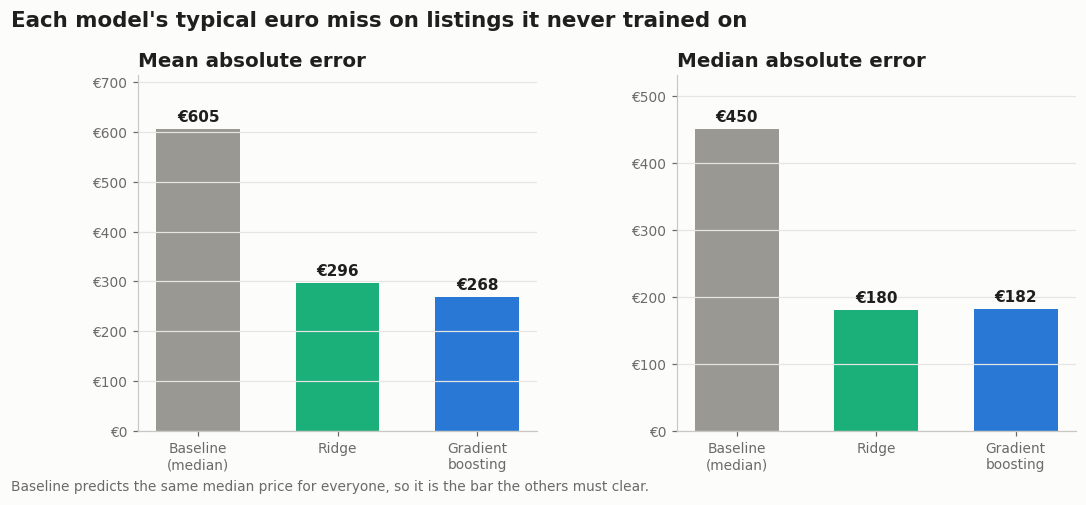

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"wspace": 0.35})
names = list(report.index)
colors = [MODEL_COL[n] for n in names]
pretty = {"baseline_median": "Baseline\n(median)", "ridge": "Ridge", "gradient_boosting": "Gradient\nboosting"}
xl = [pretty[n] for n in names]

for ax, metric, title in zip(axes, ["MAE_eur", "MedAE_eur"], ["Mean absolute error", "Median absolute error"]):
    vals = report[metric].to_numpy()
    bars = ax.bar(xl, vals, color=colors, width=0.6)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + vals.max() * 0.015, f"€{v:,.0f}",
                ha="center", va="bottom", fontsize=10, color=PAL["ink"], fontweight="semibold")
    ax.set_title(title, loc="left")
    ax.yaxis.set_major_formatter(EUR)
    ax.set_ylim(0, vals.max() * 1.18)

fig.suptitle("Each model's typical euro miss on listings it never trained on", x=0.02, ha="left",
             fontsize=14, fontweight="bold", color=PAL["ink"], y=1.02)
fig.text(0.02, -0.02, "Baseline predicts the same median price for everyone, so it is the bar the others must clear.",
         fontsize=9, color=PAL["muted"])
plt.show()

## 3. Actual vs predicted price

Best model by MAE: gradient_boosting


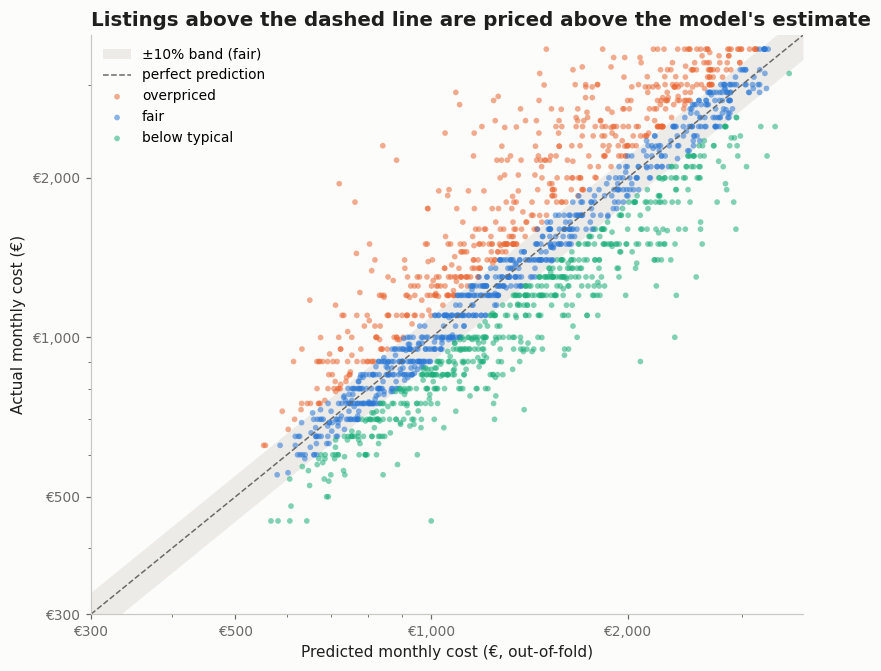

In [5]:
best = min((n for n in results if n != "baseline_median"), key=lambda n: results[n]["MAE_eur"])
pred = oof[best]
gap = actual / pred - 1
print(f"Best model by MAE: {best}")

fig, ax = plt.subplots(figsize=(7.5, 6.2))
lo, hi = 300, max(actual.max(), pred.max()) * 1.05
ax.fill_between([lo, hi], [lo * (1 - BAND), hi * (1 - BAND)], [lo * (1 + BAND), hi * (1 + BAND)],
                color=PAL["grid"], alpha=0.7, lw=0, label=f"±{int(BAND*100)}% band (fair)")
ax.plot([lo, hi], [lo, hi], color=PAL["muted"], lw=1, ls="--", label="perfect prediction")

for lab in LABEL_ORDER:
    m = labels["label"].to_numpy() == lab
    ax.scatter(pred[m], actual[m], s=14, alpha=0.55, color=LABEL_COL[lab], edgecolor="none", label=lab.replace("_", " "))

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ticks = [t for t in [300, 500, 1000, 2000, 4000, 8000, 16000] if lo <= t <= hi]
ax.set_xticks(ticks); ax.set_yticks(ticks)
ax.xaxis.set_major_formatter(EUR); ax.yaxis.set_major_formatter(EUR)
ax.xaxis.set_minor_formatter(mtick.NullFormatter()); ax.yaxis.set_minor_formatter(mtick.NullFormatter())
ax.set_xlabel("Predicted monthly cost (€, out-of-fold)")
ax.set_ylabel("Actual monthly cost (€)")
ax.set_title("Listings above the dashed line are priced above the model's estimate", loc="left")
ax.grid(False)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Reading this:** Points hug the diagonal, and the spread widens at higher rents, where a given percentage error is a larger euro amount. Orange (overpriced) points sit above the band, green (below typical) points below it, and the blue fair group fills the middle.

## 4. How far off are listings?

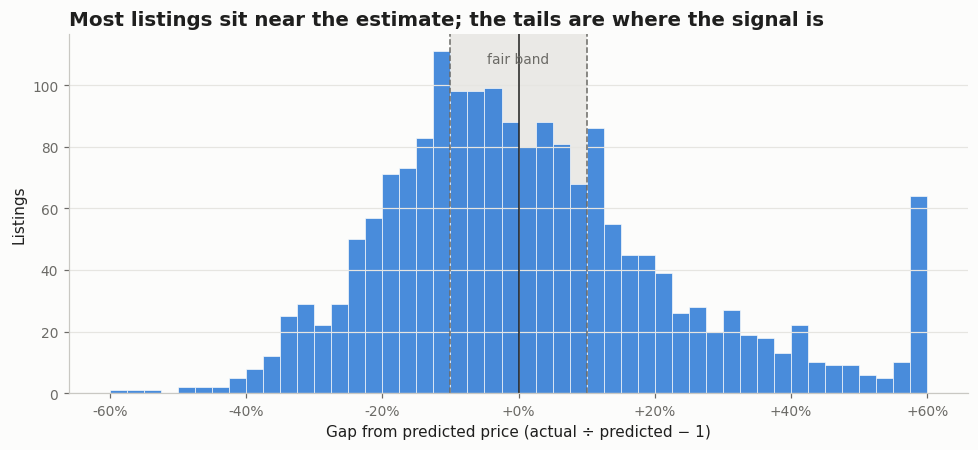

Median gap: -1.3%   share within ±10%: 38.0%


In [6]:
clip = 60
fig, ax = plt.subplots(figsize=(9, 4.2))
bins = np.arange(-clip, clip + 2.5, 2.5)
ax.hist(np.clip(gap * 100, -clip, clip), bins=bins, color=PAL["primary"], alpha=0.85, edgecolor=PAL["surface"], lw=0.5)
ax.axvspan(-BAND * 100, BAND * 100, color=PAL["grid"], alpha=0.8, lw=0, zorder=0)
ax.axvline(0, color=PAL["ink"], lw=1)
ax.axvline(-BAND * 100, color=PAL["muted"], lw=1, ls="--")
ax.axvline(BAND * 100, color=PAL["muted"], lw=1, ls="--")
ax.xaxis.set_major_formatter(PCT)
ax.set_xlabel("Gap from predicted price (actual ÷ predicted − 1)")
ax.set_ylabel("Listings")
ax.set_title("Most listings sit near the estimate; the tails are where the signal is", loc="left")
ax.text(0, ax.get_ylim()[1] * 0.92, "fair band", ha="center", color=PAL["muted"], fontsize=9)
plt.tight_layout()
plt.show()

print(f"Median gap: {np.median(gap)*100:+.1f}%   share within ±{int(BAND*100)}%: {np.mean(np.abs(gap) <= BAND)*100:.1f}%")

**Reading this:** The gap is centred near zero (median −1.3%), so the model has at most a slight tendency to predict above actual rents. Only 38% of flats fall within ±10%. That band is narrower than the model's typical error (MAPE ≈ 17%), so most flags are uncertain and a flat just outside the band may be fairly priced.

## 5. Label breakdown

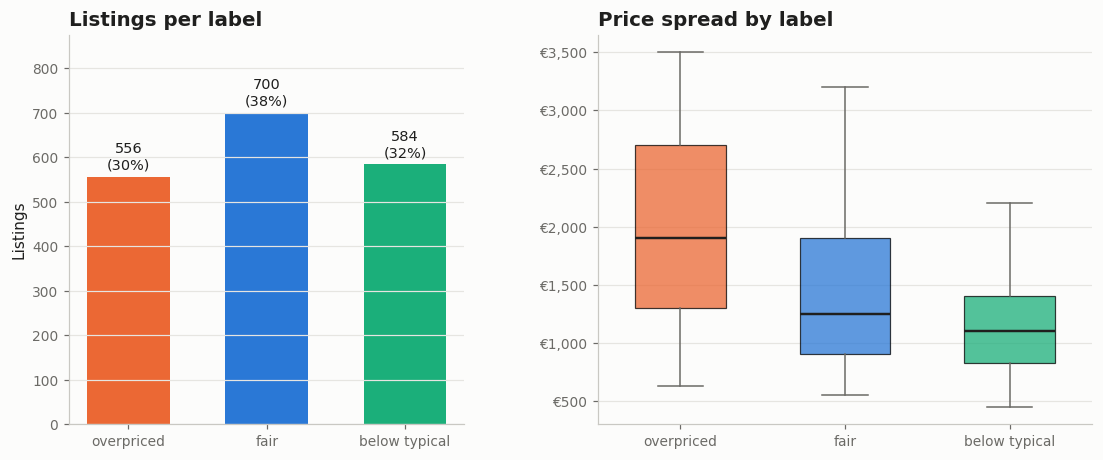

,count,median,mean
label,,,
overpriced,556,1900.0,2017.0
fair,700,1250.0,1475.0
below_typical,584,1100.0,1182.0


In [7]:
counts = labels["label"].value_counts().reindex(LABEL_ORDER)
share = counts / counts.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.25], "wspace": 0.3})

ax = axes[0]
bars = ax.bar([l.replace("_", " ") for l in LABEL_ORDER], counts.values,
              color=[LABEL_COL[l] for l in LABEL_ORDER], width=0.6)
for b, n, s in zip(bars, counts.values, share.values):
    ax.text(b.get_x() + b.get_width() / 2, n + counts.max() * 0.015, f"{n:,}\n({s:.0f}%)",
            ha="center", va="bottom", fontsize=9.5, color=PAL["ink"])
ax.set_ylim(0, counts.max() * 1.25)
ax.set_title("Listings per label", loc="left")
ax.set_ylabel("Listings")

ax = axes[1]
data = [actual[labels["label"].to_numpy() == l] for l in LABEL_ORDER]
bp = ax.boxplot(data, patch_artist=True, widths=0.55, showfliers=False,
                medianprops=dict(color=PAL["ink"], lw=1.6), whiskerprops=dict(color=PAL["muted"]),
                capprops=dict(color=PAL["muted"]), boxprops=dict(lw=0.8))
for patch, l in zip(bp["boxes"], LABEL_ORDER):
    patch.set_facecolor(LABEL_COL[l]); patch.set_alpha(0.75)
ax.set_xticks(range(1, 4), [l.replace("_", " ") for l in LABEL_ORDER])
ax.yaxis.set_major_formatter(EUR)
ax.set_title("Price spread by label", loc="left")
ax.grid(axis="y", color=PAL["grid"])
plt.tight_layout()
plt.show()

summary = (labels.assign(actual=actual)
           .groupby("label")["actual"].agg(["count", "median", "mean"])
           .reindex(LABEL_ORDER).round(0))
summary

**Reading this:** The split is 38% fair, 32% below typical and 30% overpriced. Overpriced flats have a median rent of €1,900, against €1,250 for fair and €1,100 for below typical. The labels come from the same model that predicts rent, so this ordering is expected and is not independent evidence that the labels are right.

## 6. Where do the overpriced listings cluster? (neighbourhoods)

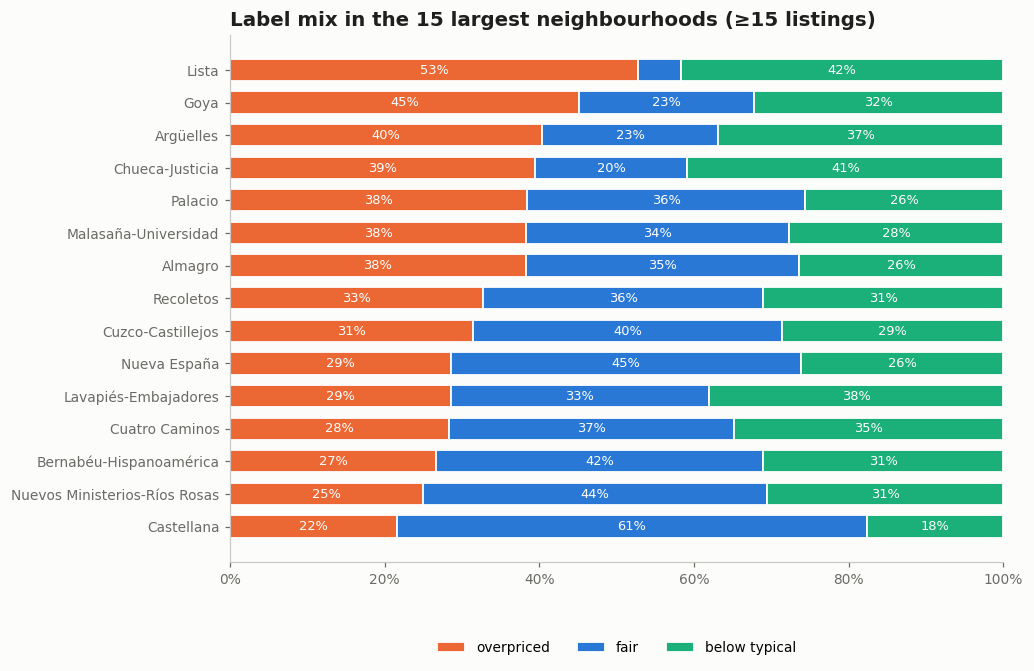

In [8]:
nb = labels.assign(neighborhood=df["Area"].to_numpy())
nb_counts = nb["neighborhood"].value_counts()
top = nb_counts[nb_counts >= 15].index[:15]
mix = (pd.crosstab(nb["neighborhood"], nb["label"], normalize="index")
         .reindex(columns=LABEL_ORDER).loc[top] * 100)
mix = mix.loc[mix["overpriced"].sort_values().index]

fig, ax = plt.subplots(figsize=(9.5, 6.2))
left = np.zeros(len(mix))
for l in LABEL_ORDER:
    ax.barh(mix.index, mix[l], left=left, color=LABEL_COL[l], height=0.68,
            label=l.replace("_", " "), edgecolor=PAL["surface"], lw=1.2)
    for i, (v, x0) in enumerate(zip(mix[l], left)):
        if v >= 9:
            ax.text(x0 + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8.5,
                    color="white" if l != "fair" else "white")
    left += mix[l].to_numpy()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(100))
ax.set_xlim(0, 100)
ax.grid(False)
ax.set_title("Label mix in the 15 largest neighbourhoods (≥15 listings)", loc="left")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.tight_layout()
plt.show()

**Reading this:** The overpriced share ranges from 22% in Castellana to 53% in Lista, with Goya (45%) also high. Lista has only 6% of its listings labelled fair. Only neighbourhoods with at least 15 flats are shown, so a handful of listings can move a bar noticeably.

## 7. Does the gap depend on the flat's type and size?

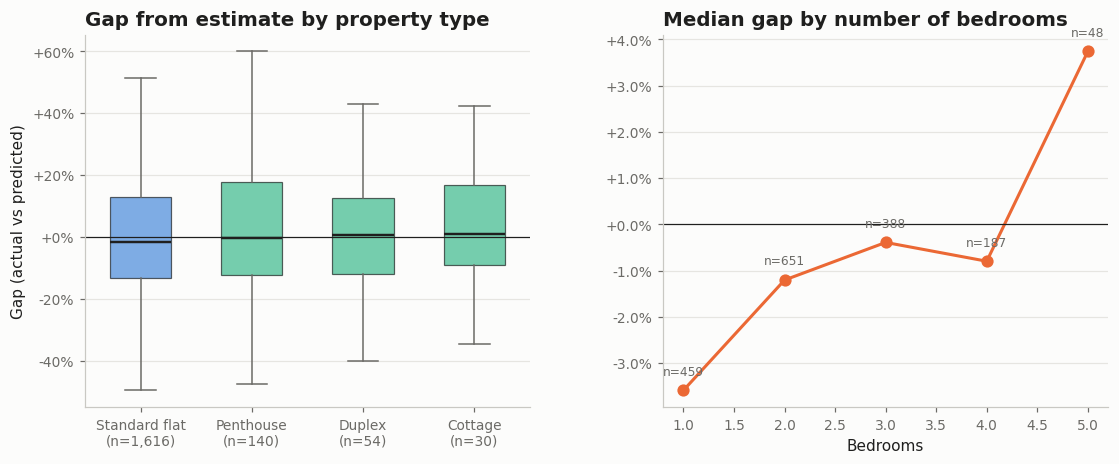

In [9]:
feat = df.copy()
feat["gap_pct"] = gap * 100
flags = ["Penthouse", "Cottage", "Duplex", "Semidetached"]
feat["type"] = np.select([feat["Penthouse"] == 1, feat["Cottage"] == 1, feat["Duplex"] == 1, feat["Semidetached"] == 1],
                         ["Penthouse", "Cottage", "Duplex", "Semidetached"], default="Standard flat")
feat["Bedrooms"] = pd.to_numeric(feat["Bedrooms"], errors="coerce")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"wspace": 0.3})

ax = axes[0]
counts = feat["type"].value_counts()
kinds = [k for k in ["Standard flat", "Penthouse", "Duplex", "Semidetached", "Cottage"] if counts.get(k, 0) >= 15]
data = [feat.loc[feat["type"] == k, "gap_pct"].clip(-60, 60) for k in kinds]
bp = ax.boxplot(data, patch_artist=True, widths=0.55, showfliers=False,
                medianprops=dict(color=PAL["ink"], lw=1.6), whiskerprops=dict(color=PAL["muted"]),
                capprops=dict(color=PAL["muted"]), boxprops=dict(lw=0.8))
for p_, k in zip(bp["boxes"], kinds):
    p_.set_facecolor(PAL["primary"] if k == "Standard flat" else PAL["teal"]); p_.set_alpha(0.6)
ax.axhline(0, color=PAL["ink"], lw=0.8)
ax.set_xticks(range(1, len(kinds) + 1), [f"{k}\n(n={counts[k]:,})" for k in kinds])
ax.yaxis.set_major_formatter(PCT)
ax.set_title("Gap from estimate by property type", loc="left")
ax.set_ylabel("Gap (actual vs predicted)")

ax = axes[1]
bed = feat[feat["Bedrooms"].between(0, 6)]
g = bed.groupby("Bedrooms")["gap_pct"].agg(["median", "count"])
g = g[g["count"] >= 20]
ax.plot(g.index, g["median"], color=PAL["accent"], marker="o", ms=7, lw=2)
for x, row in g.iterrows():
    ax.annotate(f"n={int(row['count'])}", (x, row["median"]), textcoords="offset points",
                xytext=(0, 10), ha="center", fontsize=8, color=PAL["muted"])
ax.axhline(0, color=PAL["ink"], lw=0.8)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:+.1f}%"))
ax.set_xlabel("Bedrooms")
ax.set_title("Median gap by number of bedrooms", loc="left")
plt.tight_layout()
plt.show()

**Reading this:** Standard flats sit slightly below the estimate (median −1.6%), while penthouses (−0.3%), duplexes (+0.6%) and cottages (+0.9%) sit close to zero. By bedroom count, one-bedroom flats are at −3.6% and two-bedroom flats at −1.2%, while five-bedroom flats are at +3.7%, so the model tends to underprice larger flats. Groups with fewer than 20 flats are left out.

## 8. What drives the predictions? (permutation importance)

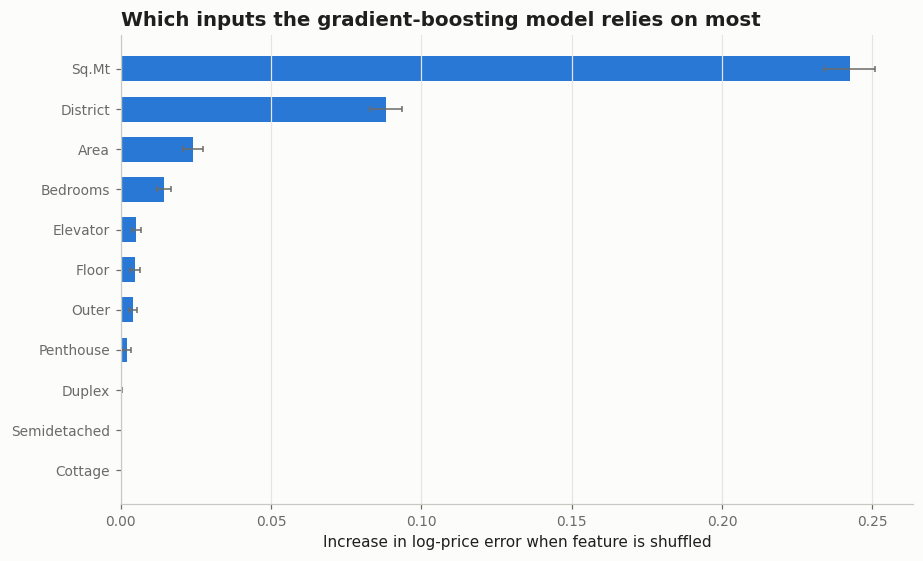

In [10]:
# Honest check: fit on 80% of listings and measure importance on the untouched 20%.
X_tr, X_te, y_tr, y_te = train_test_split(X, y_log, test_size=0.2, random_state=SEED)
gbm = make_models()["gradient_boosting"].fit(X_tr, y_tr)
perm = permutation_importance(gbm, X_te, y_te, n_repeats=10, random_state=SEED,
                              scoring="neg_mean_absolute_error")

imp = pd.DataFrame({"feature": X.columns, "mean": perm.importances_mean, "std": perm.importances_std})
imp = imp.sort_values("mean").tail(12)

fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.barh(imp["feature"], imp["mean"], xerr=imp["std"], color=PAL["primary"], height=0.62,
        error_kw=dict(ecolor=PAL["muted"], lw=1, capsize=2))
ax.set_xlabel("Increase in log-price error when feature is shuffled")
ax.set_title("Which inputs the gradient-boosting model relies on most", loc="left")
ax.grid(axis="x", color=PAL["grid"]); ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Reading this:** Flat size (`Sq.Mt`) is by far the most important input, nearly three times as influential as the next feature, district. Location comes next: district ranks above the finer neighbourhood (`Area`), likely because the 140 neighbourhoods split into many small groups. Bedrooms, elevator and floor add a little, and the property-type flags add almost nothing. Permutation importance is measured on a held-out 20%, so these ranks are not inflated by training data.

## 9. The listings the model flags most

In [11]:
view = pd.DataFrame({
    "address": (df["Address"].fillna("") + " " + df["Number"].fillna("").astype(str)).str.strip().str.slice(0, 48).to_numpy(),
    "Area": df["Area"].to_numpy(),
    "Sq.Mt": df["Sq.Mt"].to_numpy(),
    "actual_eur": actual,
    "predicted_eur": pred.round(0),
    "gap_pct": (gap * 100).round(1),
    "label": labels["label"].to_numpy(),
})
cols = ["address", "Area", "Sq.Mt", "actual_eur", "predicted_eur", "gap_pct", "label"]

def pretty(frame):
    out = frame.copy()
    out["actual_eur"] = out["actual_eur"].map("€{:,.0f}".format)
    out["predicted_eur"] = out["predicted_eur"].map("€{:,.0f}".format)
    out["gap_pct"] = out["gap_pct"].map("{:+.1f}%".format)
    return out.reset_index(drop=True)

print("Most overpriced vs the model:")
display(pretty(view.sort_values("gap_pct", ascending=False).head(10)[cols]))
print("Most underpriced vs the model:")
display(pretty(view.sort_values("gap_pct").head(10)[cols]))

Most overpriced vs the model:


,address,Area,Sq.Mt,actual_eur,predicted_eur,gap_pct,label
0,Piso en LAVAPIES,Lavapiés-Embajadores,60,"€2,300",€842,+173.2%,overpriced
1,Piso en San Isidro,San Isidro,85,"€1,950",€722,+170.2%,overpriced
2,Ático en El Viso,en El Viso,90,"€2,900","€1,090",+166.1%,overpriced
3,Piso en calle Genciana 29,Valdeacederas,80,"€2,750","€1,105",+148.9%,overpriced
4,Piso en paseo de San Francisco de Sales 15,Vallehermoso,50,"€2,160",€884,+144.4%,overpriced
5,Piso en calle Angelita Cavero 5,San Pascual,55,"€1,800",€763,+135.9%,overpriced
6,Ático en Nueva España,en Nueva España,70,"€3,500","€1,501",+133.2%,overpriced
7,Piso en calle de Don Ramón de la Cruz 93,Lista,47,"€2,430","€1,049",+131.6%,overpriced
8,Piso en calle de Ofelia Nieto 59,Valdezarza,110,"€2,850","€1,266",+125.1%,overpriced
9,Ático en Princesa 73,Argüelles,56,"€2,800","€1,246",+124.7%,overpriced


Most underpriced vs the model:


,address,Area,Sq.Mt,actual_eur,predicted_eur,gap_pct,label
0,Piso en Princesa,Argüelles,73,"€1,000","€2,364",-57.7%,below_typical
1,Estudio en avenida Real de Pinto 5,San Andrés,200,€900,"€2,093",-57.0%,below_typical
2,Estudio en calle de Martín de los Heros 53,Argüelles,60,€450,€999,-55.0%,below_typical
3,Piso en calle Viriato 38,Trafalgar,110,"€1,200","€2,376",-49.5%,below_typical
4,Piso en calle de la Princesa 3,Argüelles,85,"€1,300","€2,550",-49.0%,below_typical
5,Ático en calle san roque 12,Malasaña-Universidad,50,€730,"€1,388",-47.4%,below_typical
6,Ático en calle Martires Concepcionistas 16,Lista,200,"€1,600","€2,934",-45.5%,below_typical
7,Piso en San Hermenegildo,Chueca-Justicia,50,€700,"€1,250",-44.0%,below_typical
8,Piso en Goya,Goya,100,"€1,250","€2,214",-43.6%,below_typical
9,Piso en Goya,Goya,110,"€1,500","€2,604",-42.4%,below_typical


**Reading this:** Use these tables to spot-check the extremes. Open the addresses and confirm each record is right before acting on a flag.

## 10. Caveats

- **Relative, not true, rents.** Labels say how a flat compares with similar flats in this listing dataset (1,840 flats, after removing 44 duplicates and the 205 most expensive rents). They are not a measure of market value.
- **Circular labels.** The labels come from the same model that predicts rent. The honest test of the model is the out-of-fold euro error in section 2.
- **The band is narrower than the noise.** The ±10% band is well inside the typical error (MAPE ≈ 17%), so expect many flags to be false positives, especially near the band edges.
- **Price range.** The model is trained on rents from €450 to €3,500. It is not designed for luxury flats above that range.
- **Suspect values.** `Sq.Mt` can be extreme (the raw file goes up to 1,250 m²). `Floor` values outside −1 to 30 are set to missing. Check both against the source listings.
- **Missing values.** `Bedrooms`, `Floor`, `Outer` and `Elevator` have a few percent missing, which are median-imputed with an indicator column. `Number` is mostly missing and is not used.
- **Small groups.** Many neighbourhoods have fewer than 20 flats, so their shares are unstable.